#Seasonal Vegetation Change (NDVI Time Series)
**Student:** Osaigbovo Onaiwu-Nzegwu · **Lecturer:** Dr. Jude A. Adeleke · ISSE, AUST Abuja



## 0. Setup and connection to Google Earth Engine

In [1]:
!pip install geemap --quiet

import io
import ee
import geemap
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_ID = "ee-yourname"   # <-- replace with YOUR Cloud project ID (case-sensitive)

ee.Authenticate()            # first time: a pop-up asks you to allow Colab to use your Google account
ee.Initialize(project="isse-narsda-training-project")
print(ee.String("Earth Engine is ready").getInfo())

Earth Engine is ready


## 1. Write a function ndvi_timeseries(aoi, start_date, end_date, max_cloud=60) that takes any area of interest (an ee.Geometry) and date range, applies cloud masking, and returns a pandas DataFrame of monthly mean NDVI.


##A Reusable NDVI Time-series tool
`ndvi_timeseries(aoi, start_date, end_date, max_cloud=60)` works for **any** `ee.Geometry` and date range:

* **Filter** Sentinel-2 Level-2A (`COPERNICUS/S2_SR_HARMONIZED`) by area, dates and scene cloud cover.
* **Map** a cloud mask over every image using the Scene Classification band (SCL classes 3 = cloud shadow, 8 & 9 = cloud, 10 = cirrus), then compute NDVI = (B8 − B4) / (B8 + B4).
* **Reduce** each image to a mean NDVI over the area, and record what fraction of the area was cloud-free. Images that are mostly cloud are dropped (`min_clear`), because a mean over a few clear pixels is not representative.
* Return one row per month: mean NDVI and the number of usable images. Months with no usable image are kept as gaps (NaN) rather than silently disappearing.

The *harmonized* collection already corrects the January 2022 processing-baseline offset change, and NDVI is a ratio, so no reflectance scaling is needed.

In [2]:
S2 = "COPERNICUS/S2_SR_HARMONIZED"
CLOUD_CLASSES = [3, 8, 9, 10]   # SCL: cloud shadow, cloud medium, cloud high, cirrus


def mask_and_ndvi(img):
    """Cloud-mask one Sentinel-2 image with SCL and return NDVI plus a 0/1 'clear' band."""
    scl = img.select("SCL")
    clear = scl.remap(CLOUD_CLASSES, [0] * len(CLOUD_CLASSES), 1).rename("clear")  # 1 = clear, 0 = cloud
    ndvi = img.normalizedDifference(["B8", "B4"]).rename("NDVI").updateMask(clear)
    return ndvi.addBands(clear).copyProperties(img, ["system:time_start"])


def s2_ndvi_collection(aoi, start_date, end_date, max_cloud=60):
    """Filtered, cloud-masked NDVI collection (filter + map)."""
    return (ee.ImageCollection(S2)
            .filterBounds(aoi)
            .filterDate(start_date, end_date)
            .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", max_cloud))
            .map(mask_and_ndvi))


def ndvi_timeseries(aoi, start_date, end_date, max_cloud=60, scale=20, min_clear=0.3):
    """Monthly mean NDVI for any area and date range.

    aoi        : ee.Geometry of the area of interest
    start_date : 'YYYY-MM-DD' (inclusive)
    end_date   : 'YYYY-MM-DD' (exclusive)
    max_cloud  : maximum scene cloud percentage to accept
    scale      : pixel size in metres used for the regional mean
    min_clear  : minimum fraction of the area that must be cloud-free for an image to count
    Returns a pandas DataFrame indexed by month with columns NDVI and n_images.
    """
    col = s2_ndvi_collection(aoi, start_date, end_date, max_cloud)

    def area_mean(img):   # reduce: one feature per image
        stats = img.reduceRegion(reducer=ee.Reducer.mean(), geometry=aoi,
                                 scale=scale, maxPixels=1e9)
        return ee.Feature(None, {"date": img.date().format("YYYY-MM-dd"),
                                 "NDVI": stats.get("NDVI"),
                                 "clear": stats.get("clear")})

    rows = ee.FeatureCollection(col.map(area_mean)).getInfo()["features"]
    df = pd.DataFrame([r["properties"] for r in rows])

    months = pd.date_range(start_date, end_date, freq="MS", inclusive="left")
    if df.empty or "NDVI" not in df:
        return pd.DataFrame(index=months, columns=["NDVI", "n_images"], dtype=float)

    df = df.dropna(subset=["NDVI"])
    df = df[df["clear"] >= min_clear]
    df["date"] = pd.to_datetime(df["date"])
    monthly = df.set_index("date")["NDVI"].resample("MS").agg(["mean", "count"])
    monthly.columns = ["NDVI", "n_images"]
    monthly = monthly.reindex(months)                     # keep empty months as gaps
    monthly["n_images"] = monthly["n_images"].fillna(0).astype(int)
    monthly.index.name = "month"
    return monthly

## 2. Choose two contrasting areas in your state (for example farmland and a forest reserve, or farmland and a built-up area), each at least 2 km × 2 km, and run your function on both for at least 12 months.



##Two Contrasting Areas Chosen

**Kano State** was chosen and **Kadawa Irrigated Farmland** and **Kano City (Built-up)** were chosen as our contrasting areas: The Farmland vs Built-Up areas being studied.


In [3]:
STATE = "Kano"

# Area A: irrigated farmland of the Kano River Irrigation Project, near Kadawa (Garun Mallam LGA)
AREA_A = {"name": "Kadawa irrigated farmland", "lon": 8.420, "lat": 11.660}

# Area B: dense built-up core of Kano city (old city)
AREA_B = {"name": "Kano city (built-up)", "lon": 8.520, "lat": 12.000}

SIDE_M = 3000                              # 3 km x 3 km squares (>= 2 km required)
START, END = "2025-01-01", "2026-01-01"    # 12 months (Jan-Dec 2025)


def square_aoi(lon, lat, side_m=SIDE_M):
    """Square area of interest centred on a point."""
    if lon is None or lat is None:
        raise ValueError("Fill in lon/lat for both areas in AREA_A and AREA_B first.")
    return ee.Geometry.Point([lon, lat]).buffer(side_m / 2).bounds()


aoi_a = square_aoi(AREA_A["lon"], AREA_A["lat"])
aoi_b = square_aoi(AREA_B["lon"], AREA_B["lat"])
print("Area A (km²):", round(aoi_a.area(1).getInfo() / 1e6, 2))
print("Area B (km²):", round(aoi_b.area(1).getInfo() / 1e6, 2))

# Visual check on a satellite basemap
m = geemap.Map(center=[AREA_A["lat"], AREA_A["lon"]], zoom=10)
m.add_basemap("SATELLITE")
m.addLayer(aoi_a, {"color": "yellow"}, AREA_A["name"])
m.addLayer(aoi_b, {"color": "red"}, AREA_B["name"])
m

Area A (km²): 8.95
Area B (km²): 8.95


Map(center=[11.66, 8.42], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

In [4]:
ts_a = ndvi_timeseries(aoi_a, START, END)
ts_b = ndvi_timeseries(aoi_b, START, END)

table = pd.concat({AREA_A["name"]: ts_a, AREA_B["name"]: ts_b}, axis=1).round(3)
table.to_csv("ndvi_monthly_both_areas.csv")
table

Kadawa irrigated farmland          Kano city (built-up)         
                                NDVI n_images                 NDVI n_images
month                                                                      
2025-01-01                     0.281       14                0.085        7
2025-02-01                     0.352        4                0.093        2
2025-03-01                     0.389       10                0.091        5
2025-04-01                     0.311       12                0.082        6
2025-05-01                     0.331       13                0.072        8
2025-06-01                     0.469       13                0.072        7
2025-07-01                     0.571        2                0.103        1
2025-08-01                     0.516        4                0.059        4
2025-09-01                     0.612        6                0.107        3
2025-10-01                     0.656       12                0.115        7
2025-11-01                     0.428       12                0.103        6
2025-12-01                     0.270       10                0.091        6

## 3. Time-Series Chart and Dry/Rainy-Season Maps
Plot both time series on one chart, and produce NDVI maps for one dry-season month and
one rainy-season month for each area.


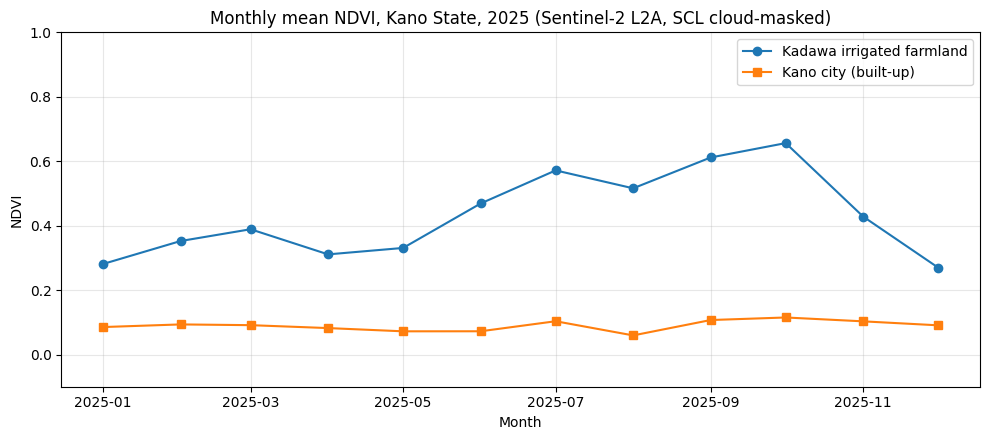

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(ts_a.index, ts_a["NDVI"], marker="o", label=AREA_A["name"])
ax.plot(ts_b.index, ts_b["NDVI"], marker="s", label=AREA_B["name"])
ax.set_title(f"Monthly mean NDVI, {STATE} State, 2025 (Sentinel-2 L2A, SCL cloud-masked)")
ax.set_ylabel("NDVI")
ax.set_xlabel("Month")
ax.set_ylim(-0.1, 1.0)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("ndvi_timeseries.png", dpi=200)   # PNG for submission
plt.show()

Choose one **dry-season** and one **rainy-season** month. Use the `n_images` column above to pick months that actually have clear imagery.
The maps are drawn as static images so they stay visible when the notebook is shared.

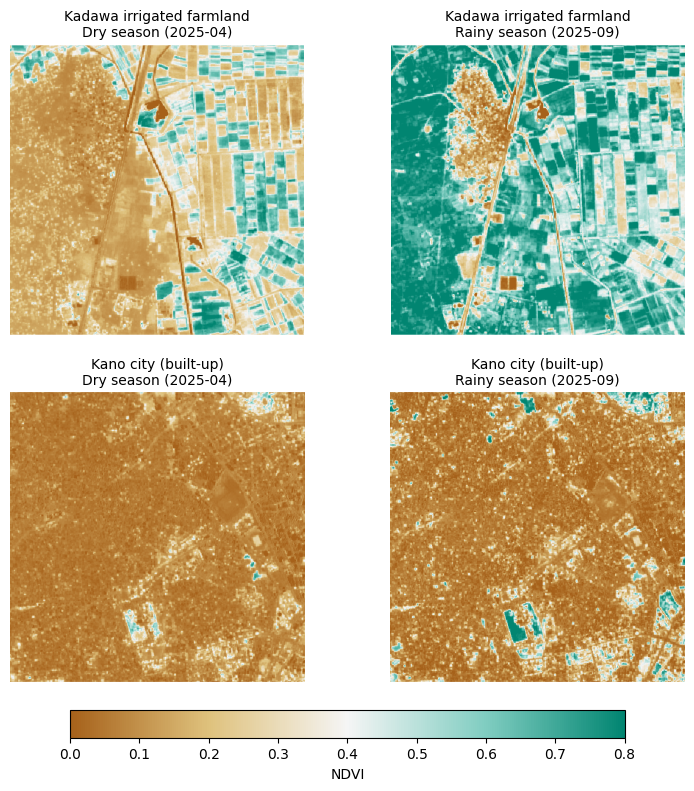

In [6]:
DRY_MONTH = "2025-04-01"     # April: peak hot dry season, fields mostly bare after harvest
RAINY_MONTH = "2025-09-01"   # September: peak of the rainy-season crop, fewer clouds than August
NDVI_VIS = {"min": 0, "max": 0.8, "palette": ["#a6611a", "#dfc27d", "#f5f5f5", "#80cdc1", "#018571"]}


def monthly_ndvi_image(aoi, month_start, max_cloud=60):
    """Median cloud-masked NDVI composite for one month, clipped to the area."""
    end = ee.Date(month_start).advance(1, "month")
    return s2_ndvi_collection(aoi, month_start, end, max_cloud).select("NDVI").median().clip(aoi)


def thumbnail(img, aoi):
    url = img.getThumbURL({**NDVI_VIS, "region": aoi, "dimensions": 400, "format": "png"})
    return Image.open(io.BytesIO(requests.get(url, timeout=120).content))


fig, axes = plt.subplots(2, 2, figsize=(9, 9))
for r, (area, aoi) in enumerate([(AREA_A, aoi_a), (AREA_B, aoi_b)]):
    for c, (label, month) in enumerate([("Dry season", DRY_MONTH), ("Rainy season", RAINY_MONTH)]):
        ax = axes[r, c]
        try:
            ax.imshow(thumbnail(monthly_ndvi_image(aoi, month), aoi))
        except Exception as e:
            ax.text(0.5, 0.5, "No clear imagery\nfor this month", ha="center", va="center")
            print(area["name"], month, "->", e)
        ax.set_title(f"{area['name']}\n{label} ({month[:7]})", fontsize=10)
        ax.axis("off")

sm = plt.cm.ScalarMappable(cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("ndvi", NDVI_VIS["palette"]),
                           norm=plt.Normalize(NDVI_VIS["min"], NDVI_VIS["max"]))
fig.colorbar(sm, ax=axes, orientation="horizontal", fraction=0.04, pad=0.04, label="NDVI")
fig.savefig("ndvi_dry_vs_rainy_maps.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Write about 300 words describing and explaining the seasonal pattern in each area, relating it to rainfall and land use, and noting at least one limitation (e.g. cloud gaps).


##Interpretation

The two areas show very different seasonal behaviour.

The Kadawa farmland has a clear seasonal cycle. NDVI was lowest in December (0.27) and January (0.28), rose sharply from June (0.47) with the onset of the rains, and peaked in October (0.66) before dropping quickly in November (0.43) as crops were harvested. This matches Kano's rainy season (roughly June to September) and the time crops take to reach full canopy, which is why the peak comes at the end of the rains rather than in the middle. There is also a smaller rise in February–March (0.39) followed by a dip in April (0.31). I interpret this as dry-season irrigated cropping under the Kano River Irrigation Project, followed by harvest and bare fields in the hottest month.

Kano city stayed low and almost flat all year (0.06–0.12), with only a slight increase in September–October from trees and gardens. Rooftops, roads, and bare ground do not respond to rainfall, so the city changed by only about 0.06 across the year compared with about 0.39 for the farmland.
The dry/rainy maps support this. In April the plots east of the canal were already green while the land west of the canal was bare. This shows the difference between irrigated and rain-fed land within the same square. By September almost the whole square was green except the village and roads. The city maps hardly changed between the two months, apart from a few parks and gardens that turned green.

**Limitations**
- The number of usable images varied a lot between months. Rainy-season cloud reduced it in July (2 farmland images, 1 city image) and August (4 each), so the August dip (0.52) may partly reflect leftover cloud or haze rather than a real drop in vegetation. February also had few images (4 and 2) despite being dry, probably because of Harmattan dust haze, so the February value is less reliable. In most months, the city had about half as many usable images as the farmland, likely due to differences in satellite orbit and tile coverage, so its monthly means rest on fewer observations.
- The farmland square is not pure cropland. It includes a village, canals, and roads, which lowers its mean NDVI.
- The analysis covers only one year (2025), so it cannot show whether this pattern is typical.

